# 08 · End-to-end DistilBERT
**Owner:** Dhanvin Vadlamudi

Phase 2. The "language only" baseline: DistilBERT reads the premise and the hypothesis together and says
valid / not valid directly, with **no parser and no graph**. We fine-tune it on the same train split as Phase 1,
check it on validation and test it once on the three test sets from notebook 06.

The training code lives in `src/c2c/transformer.py`. Training takes about an hour on an Apple M3 laptop.

In [1]:
# ─── IMPORTS ─────
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, "../src")
from c2c.transformer import load_model, fine_tune, predict_proba, DEVICE

In [2]:
# ─── LOAD DATA ─────
train = pd.read_csv("../data/processed/train.csv")
validation = pd.read_csv("../data/processed/validation.csv")
test_sets = pd.read_csv("../data/processed/test_sets.csv")
print(train.shape, validation.shape, test_sets.shape)

(35340, 7) (1026, 7) (5654, 10)


In [3]:
# ─── STEP 1: HOW LONG ARE THE INPUTS? ─────
# DistilBERT can read at most 512 tokens (word pieces)
tokenizer, model = load_model(num_labels=2, seed=42)

train_premises = train.drop_duplicates("premise_id")
test_premises = test_sets[test_sets["test_set"] == "original"].drop_duplicates("premise_id")
train_tokens = train_premises["premise"].apply(lambda p: len(tokenizer(p)["input_ids"]))
test_tokens = test_premises["premise"].apply(lambda p: len(tokenizer(p)["input_ids"]))

print("train premises over 512 tokens:", (train_tokens > 512).sum(), "of", len(train_tokens))
print("test premises over 512 tokens: ", (test_tokens > 512).sum(), "of", len(test_tokens))

train premises over 512 tokens: 160 of 400
test premises over 512 tokens:  0 of 21


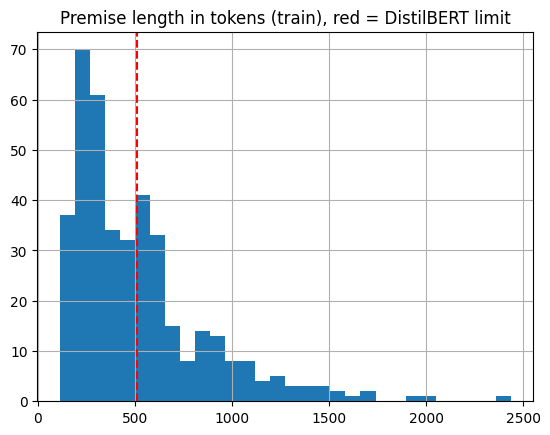

In [4]:
train_tokens.hist(bins=30)
plt.axvline(512, color="red", linestyle="--")
plt.title("Premise length in tokens (train), red = DistilBERT limit")
plt.savefig("../report/figures/e2e_input_length.png", dpi=150, bbox_inches="tight")
plt.show()

160 of the 400 train premises (all with 6 variables) are longer than 512 tokens, so DistilBERT only sees their
first part (we cut the premise and always keep the hypothesis). The test premises are shorter and fit. Our graph pipeline has no such
limit, because the parser reads the whole premise.

In [5]:
# ─── STEP 2: FINE-TUNE ─────
# 1 epoch over the 35,340 train rows, batch size 8, learning rate 3e-5
# fixed_length=True pads every batch to 512 tokens, so memory stays flat (about 4.4 GB) on an 8 GB laptop
# balanced=True weights the rare valid class more, like class_weight="balanced" in Phase 1
print("training on:", DEVICE)
fine_tune(model, tokenizer, train["premise"], train["label"], text_pairs=train["hypothesis"],
          epochs=1, lr=3e-5, batch_size=8, balanced=True, seed=42, fixed_length=True)

training on: cuda


epoch 1: mean loss 0.4928


In [6]:
# ─── STEP 3: VALIDATION ─────
val_proba = predict_proba(model, tokenizer, validation["premise"], validation["hypothesis"])[:, 1]
val_pred = (val_proba >= 0.5).astype(int)
y_val = validation["label"]
print("precision:", round(precision_score(y_val, val_pred), 3), " recall:", round(recall_score(y_val, val_pred), 3),
      " F1:", round(f1_score(y_val, val_pred), 3))

precision: 0.333  recall: 0.938  F1: 0.492


Validation F1 is only 0.49. The model finds almost every valid claim (recall 0.94) but also calls many invalid
claims valid (precision 0.33).

In [7]:
# ─── STEP 4: THE THREE TEST SETS ─────
# the model reads the text exactly as given (the refactorization set still has Z, Y, X, ...)
test_sets["e2e_proba"] = predict_proba(model, tokenizer, test_sets["premise_raw"], test_sets["hypothesis_raw"])[:, 1]
test_sets["e2e_pred"] = (test_sets["e2e_proba"] >= 0.5).astype(int)

original = test_sets[test_sets["test_set"] == "original"]
paraphrasing = test_sets[test_sets["test_set"] == "paraphrasing"]
refactorization = test_sets[test_sets["test_set"] == "refactorization"]

pd.DataFrame({
    "precision": [precision_score(original["label"], original["e2e_pred"]),
                  precision_score(paraphrasing["label"], paraphrasing["e2e_pred"]),
                  precision_score(refactorization["label"], refactorization["e2e_pred"])],
    "recall": [recall_score(original["label"], original["e2e_pred"]),
               recall_score(paraphrasing["label"], paraphrasing["e2e_pred"]),
               recall_score(refactorization["label"], refactorization["e2e_pred"])],
    "F1": [f1_score(original["label"], original["e2e_pred"]),
           f1_score(paraphrasing["label"], paraphrasing["e2e_pred"]),
           f1_score(refactorization["label"], refactorization["e2e_pred"])],
}, index=["original", "paraphrasing", "refactorization"]).round(3)

,precision,recall,F1
original,0.367,0.939,0.528
paraphrasing,0.301,0.547,0.388
refactorization,0.204,0.529,0.294


On the original test the F1 is 0.53, far below the 0.95 of our graph pipeline in Phase 1. It drops further on the
reworded claims (0.39) and the renamed variables (0.29). The Corr2Cause authors found the same breakdown for
fine-tuned language models.

In [8]:
# ─── STEP 5: DOES RENAMING THE VARIABLES BACK TO A-F HELP? ─────
proba = predict_proba(model, tokenizer, refactorization["premise"], refactorization["hypothesis"])[:, 1]
test_sets.loc[refactorization.index, "e2e_proba_renamed"] = proba
print("refactorization F1, raw names:     ", round(f1_score(refactorization["label"], refactorization["e2e_pred"]), 3))
print("refactorization F1, renamed to A-F:", round(f1_score(refactorization["label"], (proba >= 0.5).astype(int)), 3))

refactorization F1, raw names:      0.294
refactorization F1, renamed to A-F: 0.507


Renaming the variables back to A–F lifts the F1 from 0.29 to 0.51, close to the original test. So the model
leans on the letter names it saw in training, and our entity schema (notebook 06) helps it too.

In [9]:
# ─── STEP 6: CONFUSION MATRIX (ORIGINAL TEST) ─────
cm = confusion_matrix(original["label"], original["e2e_pred"])
tn, fp, fn, tp = cm.ravel()

In [10]:
# True Negatives:
tn

np.int64(691)

In [11]:
# False Positives:
fp

np.int64(291)

In [12]:
# False Negatives:
fn

np.int64(11)

In [13]:
# True Positives:
tp

np.int64(169)

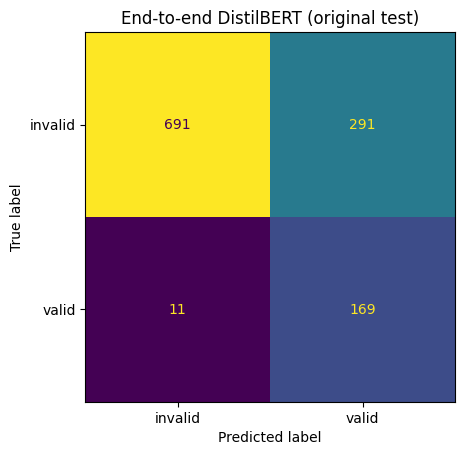

In [14]:
ConfusionMatrixDisplay(cm, display_labels=["invalid", "valid"]).plot(colorbar=False)
plt.title("End-to-end DistilBERT (original test)")
plt.savefig("../report/figures/e2e_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Almost every mistake is a false alarm: 291 invalid claims called valid, but only 11 valid claims missed.

In [15]:
# ─── STEP 7: ERROR ANALYSIS ─────
test_sets["wrong"] = test_sets["e2e_pred"] != test_sets["label"]
test_sets.pivot_table(index="relation_true", columns="test_set", values="wrong").round(3)

test_set,original,paraphrasing,refactorization
relation_true,,,
collider,0.591,0.354,0.676
confounder,0.088,0.123,0.753
direct_cause,0.255,0.291,0.365
indirect_cause,0.186,0.259,0.081


In [16]:
# share of claims called valid, against the true share
test_sets.groupby("test_set")[["label", "e2e_pred"]].mean().round(3)

,label,e2e_pred
test_set,,
original,0.155,0.396
paraphrasing,0.152,0.277
refactorization,0.152,0.395


The model calls about 40% of the claims valid when only 15% are. Without a graph it learns word patterns, not the
rule "true in every DAG that fits the premise", which is why the graph pipeline does so much better.

In [17]:
# ─── STEP 8: SAVE PREDICTIONS FOR NOTEBOOK 09 ─────
test_sets[["row_id", "test_set", "e2e_proba", "e2e_pred", "e2e_proba_renamed"]].to_csv(
    "../data/processed/e2e_predictions.csv", index=False)